In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [ ]:
window_length = 30 # number of time steps in each window
trip_fraction = 0.1 # fraction of windows followed by a trip
rng = np.random.default_rng(1) # random number generator with seed 1
t = np.arange(window_length) # time axis of 0 - 29

print(t)               

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]


Simulate 3 window (30 sensor readings per sensor) types:
- Normal
- Before trip with warning 
- Before trip with no warning

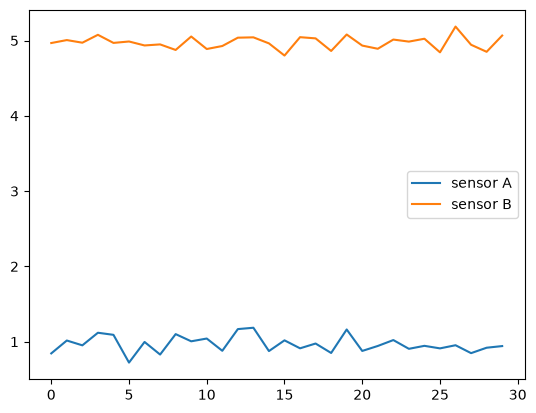

In [ ]:
def make_normal_window():
    # baselines, arbitrary units
    slope_a = rng.normal(0, 0.05) # random slow drift for A across window
    slope_b = rng.normal(0, 0.05)     

    # slope grows from nothing to almost full value. rng normal is random jitter at each time step
    sensor_a = 1.0 + slope_a * t / window_length + rng.normal(0, 0.10, window_length)
    sensor_b = 5.0 + slope_b * t / window_length + rng.normal(0, 0.10, window_length)

    return sensor_a, sensor_b

a, b = make_normal_window()
plt.plot(t, a, label="sensor A")
plt.plot(t, b, label="sensor B")
plt.legend()
plt.show()

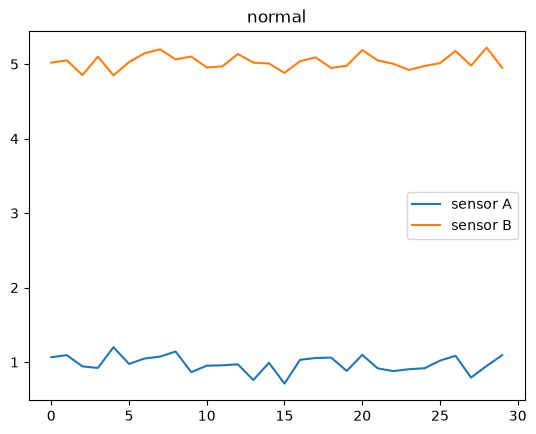

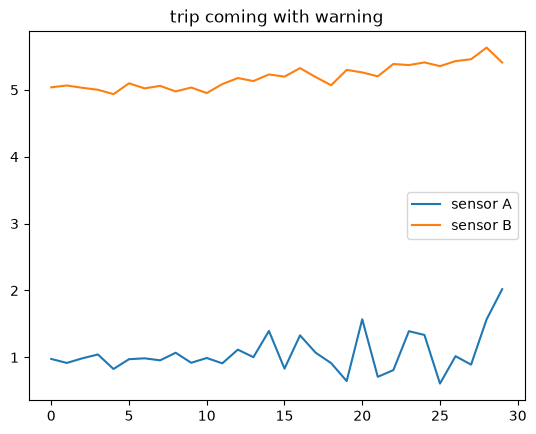

In [13]:
def make_trip_window(warning):
    sensor_a, sensor_b = make_normal_window() # initially a normal window
    if warning: 
        strength = rng.uniform(0.3, 1.0) 
        start = rng.integers(8, 22) # time step of warning start
        ramp = np.clip((t - start) / (window_length - start), 0, None) # 0 before start and increases toward 1

        jitter = rng.normal(0, 1, window_length) * 0.5 * strength * ramp # noise on A
        lean = 0.5 * strength * ramp # drift on B

        sensor_a += jitter
        sensor_b += lean

    return sensor_a, sensor_b

normal_a, normal_b = make_normal_window()
plt.plot(t, normal_a, label="sensor A")
plt.plot(t, normal_b, label="sensor B")
plt.title("normal")
plt.legend()
plt.show()

warn_a, warn_b = make_trip_window(True)
plt.plot(t, warn_a, label="sensor A")
plt.plot(t, warn_b, label="sensor B")
plt.title("trip coming with warning")
plt.legend()
plt.show()

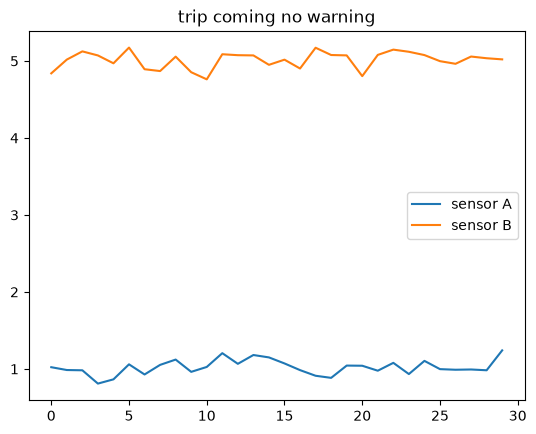

In [15]:
silent_a, silent_b = make_trip_window(False)
plt.plot(t, silent_a, label="sensor A")
plt.plot(t, silent_b, label="sensor B")
plt.title("trip coming no warning")
plt.legend()
plt.show()

Turn window into numbers (features) that can be passed into a model

Each window with 30 numbers per sensor is summarized into mean, std, slope

In [17]:
def summarize_window(sensor_a, sensor_b):
    slope_a = np.polyfit(t, sensor_a, 1)[0] # best fit slope over window 
    slope_b = np.polyfit(t, sensor_b, 1)[0]

    return [sensor_a.mean(), sensor_a.std(), slope_a, sensor_b.mean(), sensor_b.std(), slope_b]

example_a, example_b = make_normal_window()
print(summarize_window(example_a, example_b))

example_a, example_b = make_trip_window(True)
print(summarize_window(example_a, example_b))

[np.float64(0.9545624037014144), np.float64(0.09138160194265516), np.float64(-0.0019139856539801842), np.float64(5.015758473721727), np.float64(0.10460647795694604), np.float64(0.0017427629212240878)]
[np.float64(0.9625931984467205), np.float64(0.14224961035821196), np.float64(-0.0018282483162419146), np.float64(5.051182631684758), np.float64(0.14539646759107078), np.float64(0.006886536106347311)]


Turn into a dataset 
- 3000 windows as examples for the rows, each with 6 features
- Final column is whether trip occurred (weighted random to decide if there is a trip, another random to decide if there is a warning)

In [ ]:
n_windows = 3000          
warning_fraction = 0.8 # fraction of trips with a warning

features = ["a_mean", "a_std", "a_slope", "b_mean", "b_std", "b_slope"]
rows = []              
labels = [] # 1 if trip, 0 if no trip

for i in range(n_windows):
    trip = rng.random() < trip_fraction # trip_fraction true 10% of the time
    if trip:
        warn = rng.random() < warning_fraction
        sensor_a, sensor_b = make_trip_window(warn)
    else:
        sensor_a, sensor_b = make_normal_window()

    rows.append(summarize_window(sensor_a, sensor_b))
    labels.append(int(trip))

df = pd.DataFrame(rows, columns=features)
df["trip"] = labels
df.head()

,a_mean,a_std,a_slope,b_mean,b_std,b_slope,trip
0,0.987264,0.109575,-0.000131,4.915822,0.113808,-0.006302,0
1,0.986438,0.092555,-0.005880,4.956710,0.100947,-0.001296,0
2,0.975597,0.092614,0.003811,5.014573,0.099214,-0.003055,0
3,0.993013,0.097523,0.001082,4.986261,0.111590,0.001002,0
4,1.007325,0.090704,-0.001076,5.019382,0.088789,0.000574,0


In [20]:
print(df.shape)
print(df["trip"].mean())
print(df.groupby("trip").mean())

(3000, 7)
0.10433333333333333
        a_mean     a_std   a_slope    b_mean     b_std   b_slope
trip                                                            
0     1.000156  0.098272  0.000076  4.999932  0.098080 -0.000056
1     0.997731  0.146206 -0.000037  5.064991  0.134626  0.008468


Split data into train and test sets to set aside testing data

In [23]:
X = df[features]
y = df["trip"] # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(2400, 6) (600, 6)
0.10416666666666667 0.105


Create a baseline model

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

print(baseline.score(X_test, y_test)) # accuracy
print(baseline.predict(X_test).sum()) # total trips predicted

0.895
0


Fit one logistic regression (no tuning)

In [29]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# probability of a trip for the first 10 training windows
print(model.predict_proba(X_train)[:10, 1].round(3))
# target labels
print(y_train.values[:10])

# weights of features
weights = pd.Series(model[-1].coef_[0], index=features)
print(weights.round(2))

[0.061 0.011 0.049 0.179 0.003 0.042 0.007 0.078 0.011 0.014]
[0 0 0 0 0 0 0 0 0 0]
a_mean    -0.23
a_std      1.50
a_slope    0.20
b_mean     0.44
b_std      0.60
b_slope    1.34
dtype: float64


Tune C using cross validation

In [38]:
param_grid = {"logisticregression__C": np.logspace(-3, 2, 12)} #0.001 to 100

grid = GridSearchCV(model, param_grid, cv=5, scoring="average_precision")
grid.fit(X_train, y_train)

print(np.logspace(-3, 2, 12))
print(grid.best_params_)
print(grid.best_score_)

[1.00000000e-03 2.84803587e-03 8.11130831e-03 2.31012970e-02
 6.57933225e-02 1.87381742e-01 5.33669923e-01 1.51991108e+00
 4.32876128e+00 1.23284674e+01 3.51119173e+01 1.00000000e+02]
{'logisticregression__C': np.float64(0.0657933224657568)}
0.8588381000094454


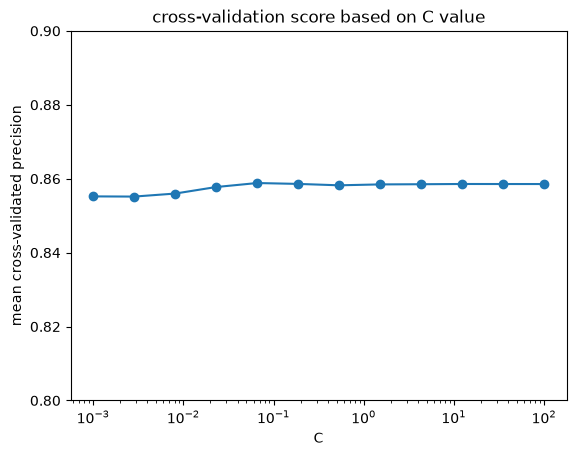

In [46]:
results = pd.DataFrame(grid.cv_results_)

c_values = results["param_logisticregression__C"].astype(float)
scores = results["mean_test_score"]

plt.plot(c_values, scores, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("mean cross-validated precision")
plt.title("cross-validation score based on C value")
plt.ylim(0.8, 0.9)
plt.show()

Differences this small are likely noise from fold to fold

Choose highest scoring C but exact C should not matter much